# Unit 2 — Assignment 3: Eigenvalues & Eigenvectors

**Team members:** Norah Alsuwailem, Raghad Alasmari, Fahad Al-Nahi, Rawan Alsubaie

## Objectives
- Identify eigenvectors using matrix-vector multiplication.
- Calculate eigenvalues and eigenvectors **manually**.
- Verify numerical results using NumPy.
- Interpret eigenvalues geometrically.
- Diagonalize a matrix and verify the reconstruction.
- Explain how eigenvalues and eigenvectors are used in Principal Component Analysis (PCA).

**Main matrix used in Missions 1, 2, 3, and 5:**

$$
A=\begin{bmatrix}2&1\\1&2\end{bmatrix}
$$

> **Method:** Each mission contains a question, manual explanation, Python verification, and an AI Insight answer. Eigenvector signs and scales may differ from NumPy outputs: both are valid if $Av=\lambda v$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
A = np.array([[2, 1], [1, 2]], dtype=float)
print("Matrix A:\n", A)

Matrix A:
 [[2. 1.]
 [1. 2.]]


---
# Mission 1 — Discovering Eigenvectors

## Given vectors

$$v_1=\begin{bmatrix}1\\1\end{bmatrix},\qquad v_2=\begin{bmatrix}1\\-1\end{bmatrix}$$

## Manual calculations

**1. Multiply $A$ by $v_1$:**

$$
Av_1=\begin{bmatrix}2&1\\1&2\end{bmatrix}\begin{bmatrix}1\\1\end{bmatrix}
=\begin{bmatrix}2(1)+1(1)\\1(1)+2(1)\end{bmatrix}
=\begin{bmatrix}3\\3\end{bmatrix}=3v_1.
$$

**2. Multiply $A$ by $v_2$:**

$$
Av_2=\begin{bmatrix}2&1\\1&2\end{bmatrix}\begin{bmatrix}1\\-1\end{bmatrix}
=\begin{bmatrix}2(1)+1(-1)\\1(1)+2(-1)\end{bmatrix}
=\begin{bmatrix}1\\-1\end{bmatrix}=1v_2.
$$

**3–5. Compare directions and identify eigenvectors:** Both $v_1$ and $v_2$ stay on their **original lines**. $v_1$ becomes three times longer while $v_2$ stays unchanged. Both are eigenvectors because multiplying by $A$ only scales them, and does not rotate them to another line.

In [2]:
v1 = np.array([1, 1], dtype=float)
v2 = np.array([1, -1], dtype=float)

Av1 = A @ v1
Av2 = A @ v2
print("A @ v1 =", Av1, "| 3 * v1 =", 3 * v1)
print("A @ v2 =", Av2, "| 1 * v2 =", 1 * v2)
assert np.allclose(Av1, 3 * v1)
assert np.allclose(Av2, 1 * v2)
print("Both eigenvector equations are verified.")

A @ v1 = [3. 3.] | 3 * v1 = [3. 3.]
A @ v2 = [ 1. -1.] | 1 * v2 = [ 1. -1.]
Both eigenvector equations are verified.


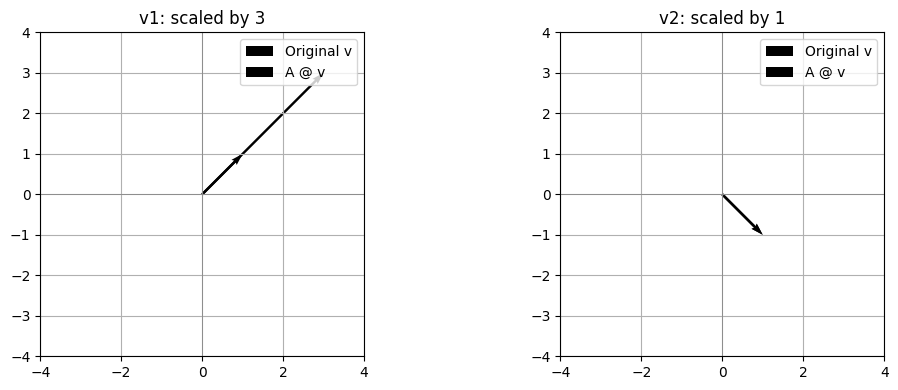

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, v, transformed, title in zip(
    axes, [v1, v2], [Av1, Av2], ["v1: scaled by 3", "v2: scaled by 1"]
):
    ax.quiver(0, 0, v[0], v[1], angles="xy", scale_units="xy", scale=1, label="Original v")
    ax.quiver(0, 0, transformed[0], transformed[1], angles="xy", scale_units="xy", scale=1, label="A @ v")
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)
    ax.set_aspect("equal"); ax.grid(True); ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(title); ax.legend()
plt.tight_layout()
plt.show()

### AI Insight — Why do most vectors change direction while only a few remain on the same line?

A matrix transformation generally mixes the components of a vector, which can change its direction. Eigenvectors are **special nonzero vectors** lying along directions that the transformation preserves. For this matrix, the lines along $(1,1)$ and $(1,-1)$ are preserved; other directions generally change. Any nonzero multiple of either eigenvector is also an eigenvector, so there are infinitely many eigenvectors along these two lines.

---
# Mission 2 — Finding Eigenvalues

## Manual calculation: characteristic equation

Eigenvalues satisfy $\det(A-\lambda I)=0$, where $I$ is the identity matrix.

$$
A-\lambda I=\begin{bmatrix}2-\lambda&1\\1&2-\lambda\end{bmatrix}.
$$

For a $2\times2$ matrix, $\det\begin{bmatrix}a&b\\c&d\end{bmatrix}=ad-bc$.

$$
\begin{aligned}
\det(A-\lambda I)&=(2-\lambda)(2-\lambda)-(1)(1)\\
&=(2-\lambda)^2-1\\
&=4-4\lambda+\lambda^2-1\\
&=\lambda^2-4\lambda+3.
\end{aligned}
$$

Solve:

$$
\lambda^2-4\lambda+3=0
\quad\Longrightarrow\quad
(\lambda-3)(\lambda-1)=0.
$$

Therefore,

$$\boxed{\lambda_1=3,\qquad\lambda_2=1}$$

In [4]:
eigenvalues, eigenvectors = np.linalg.eig(A)
print("NumPy eigenvalues:", eigenvalues)
print("Expected eigenvalues:", [3, 1])
assert np.allclose(np.sort(eigenvalues), [1, 3])

# Verify det(A - lambda * I) ~= 0 for both roots
for lam in [3, 1]:
    determinant = np.linalg.det(A - lam * np.eye(2))
    print(f"lambda={lam}: det(A - lambda*I) = {determinant:.8f}")
    assert np.isclose(determinant, 0)
print("All eigenvalues verified.")

NumPy eigenvalues: [3. 1.]
Expected eigenvalues: [3, 1]
lambda=3: det(A - lambda*I) = 0.00000000
lambda=1: det(A - lambda*I) = 0.00000000
All eigenvalues verified.


### AI Insight — What does an eigenvalue represent during a matrix transformation?

An eigenvalue $\lambda$ tells us **how the corresponding eigenvector is scaled** by the transformation. A magnitude greater than $1$ stretches the vector, a magnitude between $0$ and $1$ shrinks it, and a negative sign reverses its direction. A zero eigenvalue maps its eigenvector to the zero vector.

---
# Mission 3 — Finding Eigenvectors

## Manual calculation for $\lambda_1=3$

Solve $(A-3I)v=0$:

$$
\begin{bmatrix}-1&1\\1&-1\end{bmatrix}
\begin{bmatrix}x\\y\end{bmatrix}=\begin{bmatrix}0\\0\end{bmatrix}.
$$

Both equations give $-x+y=0$, so $y=x$. Choose $x=1$:

$$\boxed{v_1=\begin{bmatrix}1\\1\end{bmatrix}}.$$

## Manual calculation for $\lambda_2=1$

Solve $(A-I)v=0$:

$$
\begin{bmatrix}1&1\\1&1\end{bmatrix}
\begin{bmatrix}x\\y\end{bmatrix}=\begin{bmatrix}0\\0\end{bmatrix}.
$$

Both equations give $x+y=0$, so $y=-x$. Choose $x=1$:

$$\boxed{v_2=\begin{bmatrix}1\\-1\end{bmatrix}}.$$

### Optional challenge: normalization

The length (Euclidean norm) of either vector is $\sqrt{1^2+1^2}=\sqrt{2}$.

$$
\boxed{\hat v_1=\frac{1}{\sqrt{2}}\begin{bmatrix}1\\1\end{bmatrix}},
\qquad
\boxed{\hat v_2=\frac{1}{\sqrt{2}}\begin{bmatrix}1\\-1\end{bmatrix}}.
$$

A normalized eigenvector has length $1$, but it still represents the same eigenvector direction.

In [6]:
values, vectors = np.linalg.eig(A)  # eigenvectors are COLUMNS of vectors
print("Eigenvalues:", values)
print("Eigenvectors (columns):\n", vectors)

manual_eigenpairs = [(3.0, np.array([1.0, 1.0])),
                     (1.0, np.array([1.0, -1.0]))]
for lam, vec in manual_eigenpairs:
    unit_vec = vec / np.linalg.norm(vec)
    idx = np.argmin(np.abs(values - lam))
    numpy_vec = vectors[:, idx]
    print(f"\nlambda = {lam:g}")
    print("Manual normalized vector:", unit_vec)
    print("NumPy vector:", numpy_vec)
    print("A @ v equals lambda * v:", np.allclose(A @ vec, lam * vec))
    # +v and -v (as well as nonzero scalar multiples) are equivalent eigenvectors.
    print("Matching direction (up to sign):", np.isclose(abs(unit_vec @ numpy_vec), 1.0))
    assert np.allclose(A @ vec, lam * vec)
    assert np.isclose(abs(unit_vec @ numpy_vec), 1.0)
    assert np.isclose(np.linalg.norm(unit_vec), 1)
print("Manual eigenvectors and normalized versions verified.")

Eigenvalues: [3. 1.]
Eigenvectors (columns):
 [[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]

lambda = 3
Manual normalized vector: [0.7071 0.7071]
NumPy vector: [0.7071 0.7071]
A @ v equals lambda * v: True
Matching direction (up to sign): True

lambda = 1
Manual normalized vector: [ 0.7071 -0.7071]
NumPy vector: [-0.7071  0.7071]
A @ v equals lambda * v: True
Matching direction (up to sign): True
Manual eigenvectors and normalized versions verified.


### AI Insight — Why does every eigenvalue have its own eigenvector?

By definition, an eigenvalue $\lambda$ is a number for which the equation $(A-\lambda I)v=0$ has at least one **nonzero solution** $v$. That solution is an eigenvector associated with $\lambda$. An eigenvalue may have **many** eigenvectors, not just one: every nonzero scalar multiple is also an eigenvector, and in some cases an entire higher-dimensional subspace is associated with the same eigenvalue.

---
# Mission 4 — Geometric Interpretation

The eigenvalue tells us what happens **along the corresponding eigenvector's line**.

| Eigenvalue | Scaling | Direction | Explanation |
|---|---|---|---|
| $\lambda=3$ | Length becomes $3\times$ the original | Same direction | Stretch by a factor of 3 |
| $\lambda=0.5$ | Length becomes half | Same direction | Shrink by a factor of 0.5 |
| $\lambda=-2$ | Length becomes $2\times$ the original | Reversed direction | Stretch by a factor of 2 and flip |

For example, with $v=[1,0]^T$, multiplying by an eigenvalue would give $3v=[3,0]^T$, $0.5v=[0.5,0]^T$, and $-2v=[-2,0]^T$ respectively. These are conceptual examples of how each eigenvalue acts on its associated eigenvector, **not** claims that $3$, $0.5$, and $-2$ are all eigenvalues of the matrix $A$.

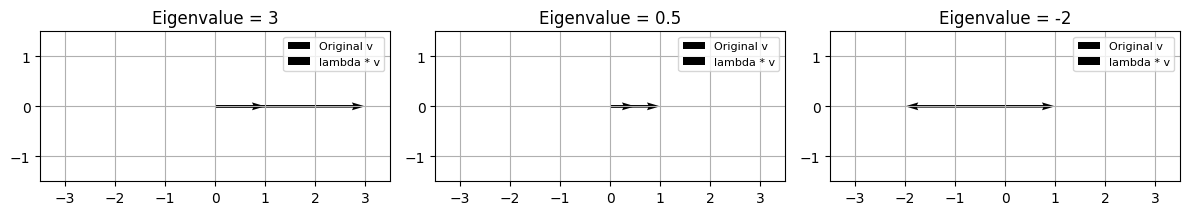

In [7]:
base = np.array([1.0, 0.0])
examples = [3, 0.5, -2]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, lam in zip(axes, examples):
    ax.quiver(0, 0, *base, angles="xy", scale_units="xy", scale=1, label="Original v")
    ax.quiver(0, 0, *(lam * base), angles="xy", scale_units="xy", scale=1, label="lambda * v")
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-1.5, 1.5)
    ax.grid(True); ax.set_aspect("equal")
    ax.set_title(f"Eigenvalue = {lam}")
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

### AI Insight — How do eigenvalues affect scaling and direction?

The **absolute value** $|\lambda|$ determines the scaling factor, while the **sign** determines whether the direction is kept or reversed. A positive eigenvalue preserves direction; a negative eigenvalue reverses direction. If $\lambda=0$, the corresponding eigenvector is mapped to zero, which has no direction.

---
# Mission 5 — Matrix Diagonalization

The diagonalization formula is

$$A=PDP^{-1}.$$

Use our manually determined eigenvectors **as columns** of $P$, ordered to match the eigenvalues in $D$:

$$
P=\begin{bmatrix}1&1\\1&-1\end{bmatrix},
\qquad
D=\begin{bmatrix}3&0\\0&1\end{bmatrix}.
$$

The determinant of $P$ is $(1)(-1)-(1)(1)=-2\ne0$, so $P$ is invertible.

$$P^{-1}=\frac{1}{-2}\begin{bmatrix}-1&-1\\-1&1\end{bmatrix}
=\begin{bmatrix}0.5&0.5\\0.5&-0.5\end{bmatrix}.$$

First multiply:

$$PD=\begin{bmatrix}3&1\\3&-1\end{bmatrix}.$$

Then:

$$
\begin{aligned}
PDP^{-1}&=\begin{bmatrix}3&1\\3&-1\end{bmatrix}
\begin{bmatrix}0.5&0.5\\0.5&-0.5\end{bmatrix}\\
&=\begin{bmatrix}2&1\\1&2\end{bmatrix}=A.
\end{aligned}
$$

**Why are diagonal matrices easier?** A diagonal matrix contains nonzero entries only on the main diagonal. Multiplication and powers are much easier, e.g. $D^k=\operatorname{diag}(3^k,1^k)$. Thus $A^k=PD^kP^{-1}$ without multiplying $A$ by itself $k$ times.

In [8]:
P = np.column_stack((v1, v2))
D = np.diag([3.0, 1.0])
P_inv = np.linalg.inv(P)
reconstructed_A = P @ D @ P_inv
print("P (eigenvectors in columns):\n", P)
print("D (matching eigenvalues):\n", D)
print("P inverse:\n", P_inv)
print("P @ D @ inv(P):\n", reconstructed_A)
print("Matches original A:", np.allclose(A, reconstructed_A))
assert np.allclose(A, reconstructed_A)

# Extra numerical illustration of the benefit of diagonalization
k = 5
print(f"A^{k} directly:\n", np.linalg.matrix_power(A, k))
print(f"A^{k} via diagonalization:\n", P @ np.linalg.matrix_power(D, k) @ P_inv)
assert np.allclose(np.linalg.matrix_power(A, k), P @ np.linalg.matrix_power(D, k) @ P_inv)

P (eigenvectors in columns):
 [[ 1.  1.]
 [ 1. -1.]]
D (matching eigenvalues):
 [[3. 0.]
 [0. 1.]]
P inverse:
 [[ 0.5  0.5]
 [ 0.5 -0.5]]
P @ D @ inv(P):
 [[2. 1.]
 [1. 2.]]
Matches original A: True
A^5 directly:
 [[122. 121.]
 [121. 122.]]
A^5 via diagonalization:
 [[122. 121.]
 [121. 122.]]


### AI Insight — Why is diagonalization useful in Machine Learning?

Diagonalization separates a suitable linear transformation into independent scaling directions, making its behavior easier to study and some matrix computations easier. Eigenvalue decomposition is also related to PCA: for a real symmetric covariance matrix, the eigenvectors give principal directions and the eigenvalues tell us the amount of variance along those directions. **Not every matrix is diagonalizable**, but real symmetric matrices, including covariance matrices, are.

---
# Mission 6 — Eigenvalues in AI (PCA)

### 1. Why is PCA used?

**Principal Component Analysis (PCA)** is used to reduce the number of features while retaining as much of the data's variance as possible. It can simplify models, decrease computation, and make high-dimensional data easier to visualize. PCA is unsupervised and preserves variance, which is not necessarily the same as preserving all information useful for prediction.

### 2. Why are eigenvalues important in PCA?

When PCA uses the **covariance matrix** of centered data, an eigenvalue measures how much variance lies along its corresponding eigenvector (principal component). Larger eigenvalues indicate directions with more variance.

### 3. Why do we sort eigenvalues from largest to smallest?

Sorting ranks the principal components by the amount of variance explained, allowing us to retain the most variable directions first.

### 4. Which eigenvectors should be selected?

Choose the eigenvectors associated with the **largest eigenvalues**. How many to retain depends on the target explained-variance ratio (e.g., 90% or 95%) and the purpose of the analysis.

### 5. What may happen if we remove the eigenvector with the largest eigenvalue?

We would discard the principal direction that accounts for the **most variance** in the data, potentially losing important structure. Whether that harms downstream prediction depends on the problem, because high variance does not always imply high predictive usefulness.

## Worked PCA example using NumPy

We use a small **sample covariance matrix** and obtain its eigenvalues and eigenvectors. Because covariance matrices are symmetric, `np.linalg.eigh` is a suitable choice and returns real eigenvalues and orthonormal eigenvectors.

In [9]:
# Synthetic data with two correlated features (reproducible example)
rng = np.random.default_rng(42)
feature_1 = rng.normal(0, 2, size=200)
feature_2 = 0.8 * feature_1 + rng.normal(0, 0.6, size=200)
X = np.column_stack([feature_1, feature_2])
X_centered = X - X.mean(axis=0)

cov_matrix = np.cov(X_centered, rowvar=False)
pca_values, pca_vectors = np.linalg.eigh(cov_matrix)
order = np.argsort(pca_values)[::-1]
pca_values = pca_values[order]
pca_vectors = pca_vectors[:, order]
explained_variance_ratio = pca_values / pca_values.sum()

print("Covariance matrix:\n", cov_matrix)
print("Sorted PCA eigenvalues:", pca_values)
print("Explained variance ratio:", explained_variance_ratio)
print("First component explains:", f"{explained_variance_ratio[0]:.2%}")

# Reduce two dimensions to one and reconstruct an approximation
principal_direction = pca_vectors[:, 0]
X_1d = X_centered @ principal_direction
X_reconstructed = np.outer(X_1d, principal_direction) + X.mean(axis=0)
print("Original X shape:", X.shape)
print("Reduced X shape:", X_1d.shape)
print("Reconstructed X shape:", X_reconstructed.shape)
assert explained_variance_ratio[0] >= explained_variance_ratio[1]

Covariance matrix:
 [[3.1112 2.4132]
 [2.4132 2.2441]]
Sorted PCA eigenvalues: [5.1295 0.2258]
Explained variance ratio: [0.9578 0.0422]
First component explains: 95.78%
Original X shape: (200, 2)
Reduced X shape: (200,)
Reconstructed X shape: (200, 2)


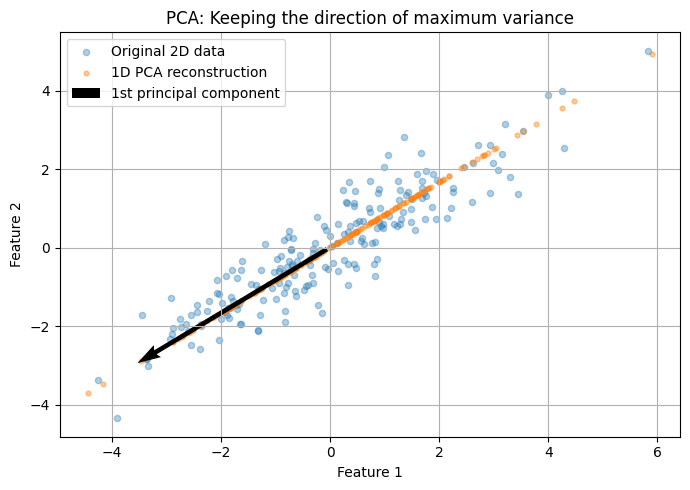

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X[:, 0], X[:, 1], alpha=0.35, s=20, label="Original 2D data")
ax.scatter(X_reconstructed[:, 0], X_reconstructed[:, 1], alpha=0.4, s=12, label="1D PCA reconstruction")
center = X.mean(axis=0)
axis_scale = 2 * np.sqrt(pca_values[0])
ax.quiver(*center, *(principal_direction * axis_scale), angles="xy", scale_units="xy", scale=1, label="1st principal component")
ax.set_xlabel("Feature 1"); ax.set_ylabel("Feature 2")
ax.set_title("PCA: Keeping the direction of maximum variance")
ax.grid(True); ax.legend()
plt.tight_layout()
plt.show()

### AI Insight — How do eigenvalues help reduce data dimensions while preserving useful information?

PCA computes principal directions from the data's covariance matrix. The eigenvalues quantify the variance carried by each direction. Selecting the eigenvectors with the largest eigenvalues and projecting the data onto them keeps the highest-variance structure in fewer dimensions. This usually reduces information loss **as measured by reconstruction variance**, although it does not guarantee the retention of all information relevant to a particular ML target.

---
# Final Summary

| Mission | Main result |
|---|---|
| 1 — Discovering Eigenvectors | $Av_1=3v_1$ and $Av_2=v_2$ |
| 2 — Finding Eigenvalues | $\lambda_1=3$ and $\lambda_2=1$ |
| 3 — Finding Eigenvectors | $v_1=[1,1]^T$ and $v_2=[1,-1]^T$ |
| 4 — Geometric Interpretation | $3$: stretch; $0.5$: shrink; $-2$: stretch and reverse |
| 5 — Diagonalization | $A=PDP^{-1}$ verified |
| 6 — PCA | Keep eigenvectors with the largest covariance eigenvalues to preserve maximum variance |

## Submission checklist

- [x] Manual calculations included
- [x] Numerical results verified using NumPy
- [x] AI Insight questions answered
- [x] Visual explanations included
- [x] Add team members 
- [ ] Prepare the separate PDF report required by the assignment